<a href="https://colab.research.google.com/github/Prasadn1234/DataScience/blob/main/Support_Bot_Evaluation_04272026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Evaluating RAG pipelines (Support Bot)

### **Why Evaluation for a RAG-Based Customer Support Bot is Necessary**  

When building a **customer support chatbot** using **Retrieval-Augmented Generation (RAG)**, evaluation is critical to ensure **accuracy, groundedness, and a trustworthy user experience**. Here’s why:

#### **1. Customer Support is High-Stakes**
- A support bot influences **financial actions**, **account decisions**, and **user trust**.  
- Even small factual errors can lead to **bad decisions** or **escalations**.

#### **2. Measuring Retrieval Quality**
- In RAG, the bot is only as good as the **documents it retrieves**.  
- We must assess whether the retriever is pulling **relevant, precise, and properly-scoped** context.

#### **3. Evaluating Generation for Coherence & Factuality**
- LLMs can be fluent but still wrong (or overly generic).  
- Evaluation helps detect:
  - **Hallucinations**  
  - **“I don’t know” failures** even when context exists  
  - **Incomplete / misleading answers**

#### **4. A Path to Iteration (and Optimization)**
Evaluation gives us a measurable loop to improve:
- Chunking strategy
- Retrieval settings
- Prompting / instruction hierarchy
- Model selection & cost


<center><img src="https://miro.medium.com/v2/resize:fit:1400/1*k3qP8mLd2NBB5Z9S9k13-A.png" width=500/></center>

---

In this notebook, we will evaluate our **Zerodha Support Bot** using **LangSmith** and a set of **LLM-as-a-judge** evaluators across four key metrics:

1. **Correctness:** Response vs Reference Answer  
2. **Relevance:** Response vs Input  
3. **Groundedness:** Response vs Retrieved Docs  
4. **Retrieval Relevance:** Retrieved Docs vs Input  


Using the above frameworks, we observe that there are quite a few parameters which we can use to evaluate the bot's responses. Based on well-known practices we shall focus on the following parameters for now.

(Source: LangSmith)

#### **Evaluation Criteria for RAG-Based Applications**

 **1. Correctness: Response vs Reference Answer**
- **Goal:** Measure *how similar/correct is the RAG chain answer, relative to a ground-truth answer.*  
- **Mode:** Requires a ground truth (reference) answer supplied through a dataset.  
- **Evaluator:** Use **LLM-as-judge** to assess answer correctness.  

**2. Relevance: Response vs Input**
- **Goal:** Measure *how well does the generated response address the initial user input.*  
- **Mode:** Does **not** require a reference answer, as it compares the response to the input question.  
- **Evaluator:** Use **LLM-as-judge** to assess helpfulness/relevance.  

**3. Groundedness: Response vs Retrieved Docs**
- **Goal:** Measure *to what extent does the generated response agree with the retrieved context.*  
- **Mode:** Does **not** require a reference answer, as it compares the response to the retrieved context.  
- **Evaluator:** Use **LLM-as-judge** to assess hallucinations / faithfulness.  

**4. Retrieval Relevance: Retrieved Docs vs Input**
- **Goal:** Measure *how relevant are my retrieved results for this query.*  
- **Mode:** Does **not** require a reference answer, as it compares the query to the retrieved context.  
- **Evaluator:** Use **LLM-as-judge** to assess relevance of retrieval.  

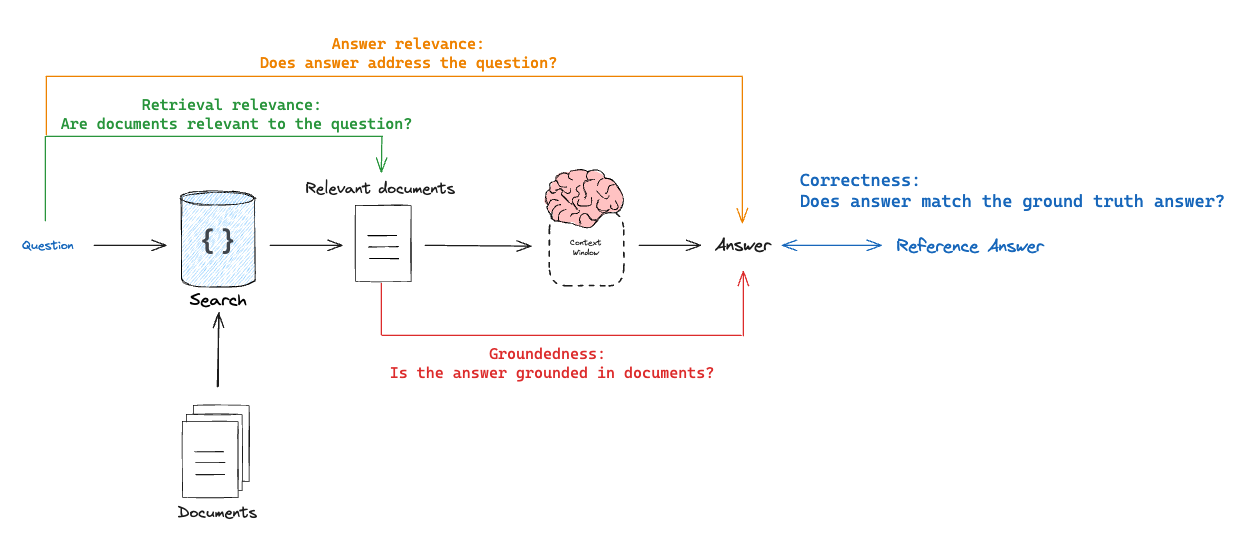

---

## 1. Setup & Installation

We will start by installing the necessary libraries (**pinned stable versions** for consistency).

#### RUN THE FOLLOWING CODE & CONTINUE WITH THE NEXT SECTION


In [ ]:
# Installing pinned stable versions
!pip install langchain==0.3.27

# Installing LangChain Community for community-contributed integrations, tools, and connectors.
!pip install langchain-community==0.0.10

# Installing LangChain OpenAI to integrate OpenAI models into LangChain workflows.
!pip install langchain-openai==0.3.0

# Installing LangChain Hub to access and manage pre-built prompts, chains, and agents.
!pip install langchainhub==0.1.14

# Installing FAISS CPU for efficient vector similarity search on embeddings.
!pip install faiss-cpu==1.10.0

# Installing Tavily Python SDK for real-time web search integration in LLM applications.
!pip install tavily-python==0.3.0

# Installing BeautifulSoup4 for parsing and extracting data from HTML and XML content.
!pip install beautifulsoup4==4.12.2

# Installing Gradio to build interactive web interfaces for AI models.
!pip install gradio==3.38.0

# Installing Gradio Client to programmatically interact with Gradio apps.
!pip install gradio_client==0.2.10
!pip install -U langsmith

  Using cached langchain_core-0.1.53-py3-none-any.whl.metadata (5.9 kB)
  Using cached langsmith-0.0.92-py3-none-any.whl.metadata (9.9 kB)
INFO: pip is looking at multiple versions of langchain-core to determine which version is compatible with other requirements. This could take a while.
  Using cached langchain_core-0.1.52-py3-none-any.whl.metadata (5.9 kB)
  Using cached langchain_core-0.1.51-py3-none-any.whl.metadata (5.9 kB)
  Using cached langchain_core-0.1.50-py3-none-any.whl.metadata (5.9 kB)
  Using cached langchain_core-0.1.49-py3-none-any.whl.metadata (5.9 kB)
  Using cached langchain_core-0.1.48-py3-none-any.whl.metadata (5.9 kB)
  Using cached langchain_core-0.1.47-py3-none-any.whl.metadata (5.9 kB)
  Using cached langchain_core-0.1.46-py3-none-any.whl.metadata (5.9 kB)
INFO: pip is still looking at multiple versions of langchain-core to determine which version is compatible with other requirements. This could take a while.
  Using cached langchain_core-0.1.45-py3-none-any

**IMPORTANT:** Restart Runtime after installation for changes to take effect!  

- In Google Colab: `Runtime → Restart session`  
- Then re-run the notebook from the top.


In [ ]:
import os
import getpass
import bs4
import json
from typing_extensions import Annotated, TypedDict
from langsmith import Client, traceable

from langchain_openai import ChatOpenAI
from langchain_openai import OpenAIEmbeddings
from langchain_community.document_loaders import WebBaseLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS

/usr/local/lib/python3.12/dist-packages/langchain_community/document_loaders/blob_loaders/file_system.py:5: LangChainDeprecationWarning: As of langchain-core 0.3.0, LangChain uses pydantic v2 internally. The langchain_core.pydantic_v1 module was a compatibility shim for pydantic v1, and should no longer be used. Please update the code to import from Pydantic directly.

For example, replace imports like: `from langchain_core.pydantic_v1 import BaseModel`
with: `from pydantic import BaseModel`
or the v1 compatibility namespace if you are working in a code base that has not been fully upgraded to pydantic 2 yet. 	from pydantic.v1 import BaseModel

  from langchain_community.document_loaders.blob_loaders.schema import Blob, BlobLoader
/usr/local/lib/python3.12/dist-packages/langchain_community/document_loaders/__init__.py:218: LangChainDeprecationWarning: As of langchain-core 0.3.0, LangChain uses pydantic v2 internally. The langchain_core.pydantic_v1 module was a compatibility shim for py

### Introduction to LangSmith

LangSmith is a debugging, monitoring, and evaluation platform for LLM-based applications, developed by the creators of LangChain. It helps developers track, test, and optimize their AI workflows by providing insights into prompt behavior, latency, token usage, and model performance. LangSmith allows for seamless integration with LangChain applications, making it easier to debug complex chains, compare model outputs, and improve reliability in production deployments.

<center><img src="https://miro.medium.com/v2/resize:fit:1400/1*fOoaEJnm2WC5S9zCFNqMJA.png" width = 500/></center>

Before proceeding further, you should create a **LangSmith API key**. Here are the steps:

- Go to https://www.langchain.com/langsmith  
- Create a new account (or sign up using Google/GitHub).  
- While onboarding, you will be given an **API key**. Copy it for further usage in this notebook.  
- This is how your personal dashboard would look like:

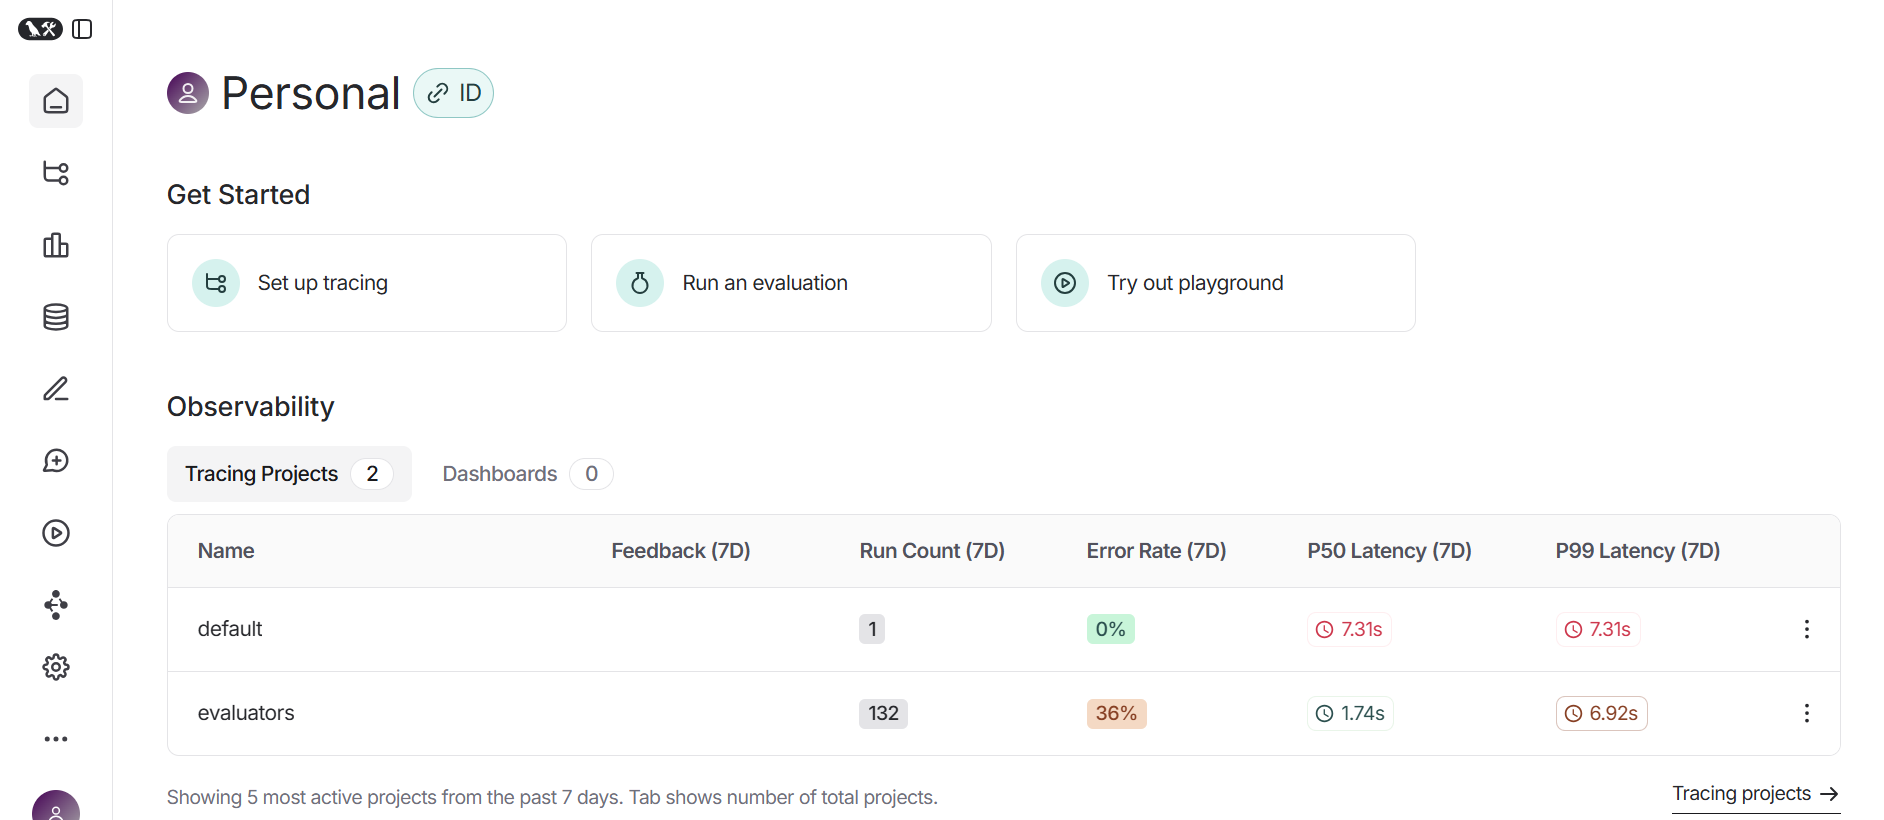

---

### API Keys (Local Runtime)

You will need:
- Your **OpenAI API Key**  
- Your **LangSmith API Key** (created above)

The next two code cells will securely prompt you to enter these keys.


In [ ]:
os.environ["OPENAI_API_KEY"] = getpass.getpass("Enter OpenAI API Key: ")

Enter OpenAI API Key: ··········


In [ ]:
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_API_KEY"] = getpass.getpass("Enter LangSmith API Key: ")

Enter LangSmith API Key: ··········


In the upcoming code, we shall rebuild our **Zerodha Support Bot** and connect it with **LangSmith Tracing**.

This will include:
- Loading Zerodha’s knowledge base  
- Chunking & indexing into a vector store  
- Creating a retriever and an LLM  
- Running a traced RAG function

#### RUN THE FOLLOWING CODE & CONTINUE WITH THE NEXT SECTION

NOTE: The following blocks are the same “core RAG build” steps you’ve seen earlier — we’re reusing them here so evaluation is reproducible end-to-end.


In [ ]:
print("Loading knowledge base from Zerodha...")
loader = WebBaseLoader("https://zerodha.com/")
docs = loader.load()
print(f"Loaded {len(docs)} documents.")

Loading knowledge base from Zerodha...
Loaded 1 documents.


In [ ]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)
splits = text_splitter.split_documents(docs)
print(f"Created {len(splits)} chunks.")

Created 9 chunks.


In [ ]:
embeddings = OpenAIEmbeddings()
vectorstore = FAISS.from_documents(splits, embeddings)
retriever = vectorstore.as_retriever()

In [ ]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.2)

### How LangSmith helps in Evaluation?

LangSmith uses **Tracing**, a powerful tool for understanding the behavior of your LLM application. Tracing is designed to help developers debug and optimize LLM-based applications by capturing and visualizing the execution flow of a LangChain pipeline.

Tracing records detailed information about each step in your chain, including:  

1. **Input & Output Tracking** – Captures inputs, outputs, and intermediate steps in a structured format.  
2. **Execution Flow Visualization** – Shows how prompts, functions, and models interact within the pipeline.  
3. **Latency & Cost Analysis** – Measures execution time and token usage at each step to optimize efficiency.  
4. **Error Debugging** – Identifies failures, unexpected outputs, and bottlenecks.  
5. **Comparison & Experimentation** – Enables versioning and systematic evaluation across different runs.

---

#### -------------------------TODAY'S CODE STARTS HERE -------------------------


In [ ]:
# Add decorator so this function is traced in LangSmith
@traceable()
def rag_bot(question: str) -> dict:
    # Provide a specific context instruction based on Zerodha
    docs = retriever.invoke(question)
    docs_string = "\n\n".join(doc.page_content for doc in docs)

    instructions = f"""You are a helpful customer support assistant for Zerodha.
    Use the following retrieved context to answer the user's question.
    If you don't know the answer, just say that you don't know.
    Context: {docs_string}"""

    ai_msg = llm.invoke([
        {"role": "system", "content": instructions},
        {"role": "user", "content": question},
    ])

    return {"answer": ai_msg.content, "documents": docs}

In [ ]:
rag_bot("What is Coin?")

{'answer': "Coin is Zerodha's platform for investing in mutual funds. It allows users to invest in a variety of mutual funds directly, without any commission or intermediary fees. The platform is designed to make mutual fund investments simple and accessible for everyone.",
 'documents': [Document(metadata={'source': 'https://zerodha.com/', 'title': 'Zerodha: Online brokerage platform for stock trading & investing', 'description': 'Online stock brokerage platform for trading and investing in stocks, futures, options, commodities, currency, ETFs, mutual funds, and bonds.', 'language': 'No language found.'}, page_content='Zerodha: Online brokerage platform for stock trading & investing\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nSignup\n\n\nAbout\n\n\nProducts\n\n\nPricing\n\n\nSupport\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nSignup\n\n\nOpen account\n\n\nAbout\n\n\nProducts\n\n\nPricing\n\n\nSupport\n\n\n\n\n\n\n\nKite\n\n\n\n                        Trading platform\n                

This function implements a Retrieval-Augmented Generation (RAG) bot that retrieves relevant documents from Zerodha’s knowledge base and uses an AI language model to generate a response. It is designed to work with **LangSmith** for automatic tracing and monitoring.

Key Components:

1. **LangSmith Tracing (`@traceable()`)**
    - The function is decorated with `@traceable()`, which allows LangSmith to automatically trace and log the function’s execution.
    - This helps in debugging, performance tracking, and understanding how the bot behaves over time.
2. **Document Retrieval (`retriever.invoke(question)`)**
    - The function uses a retriever to fetch relevant documents based on the user’s question.
3. **Formatting Retrieved Documents (`docs_string`)**
    - The retrieved documents are combined into a single context string for the LLM.
4. **Instruction + Context Prompting**
    - We provide role instructions (“You are a helpful customer support assistant for Zerodha…”) and enforce *context-first answering*.
5. **LLM Call**
    - The model generates the final answer using the retrieved context.

---

With the RAG application loaded, let's go ahead and build a **RAG evaluation workflow**.

The workflow consists of three main steps:

- Creating a dataset with questions and their expected answers  
- Running our RAG application on those questions  
- Using evaluators to measure how well the application performed, looking at factors like:
   - Correctness  
   - Relevance  
   - Groundedness  
   - Retrieval relevance  

### Evaluation Set

We will start off with a very simple dataset containing **3 questions**.


In [ ]:
client = Client()

# Define the examples for the dataset
examples = [
    (
        "What exactly does Zerodha do?",
        "Zerodha is a stockbroker in India that offers a discount pricing model. They provide platforms for investing in stocks, derivatives, mutual funds, and more."
    ),
    (
        "Tell me about Coin and what it is used for.",
        "Coin is a platform by Zerodha that allows you to buy mutual funds directly from asset management companies without paying any commission."
    ),
    (
        "Is it free to start investing in mutual funds with you?",
        "Yes, direct mutual fund investments through Zerodha are absolutely free with zero commissions."
    )
]

# Create the dataset and examples in LangSmith
dataset_name = "zerodha_support_bot_eval_v1"
if not client.has_dataset(dataset_name=dataset_name):
    dataset = client.create_dataset(dataset_name=dataset_name)
    client.create_examples(
        inputs=[{"question": q} for q, _ in examples],
        outputs=[{"answer": a} for _, a in examples],
        dataset_id=dataset.id,
    )
    print(f"Created dataset {dataset_name} with {len(examples)} examples.")
else:
    print(f"Dataset {dataset_name} already exists.")

Dataset zerodha_support_bot_eval_v1 already exists.


### Code Explanation: Creating a LangSmith Evaluation Dataset

1. **Initialize LangSmith Client**
   - We establish a connection with LangSmith using `Client()`.
   - This client manages dataset creation, storing examples, and tracking experiment runs.

2. **Define Example Queries and Reference Answers**
   - We create a small list of question–answer pairs.
   - Each entry includes:
     - The user question (input)
     - The ideal / expected answer (ground truth)

3. **Check for Existing Dataset**
   - If the dataset already exists, we avoid duplicating it.
   - If it doesn’t exist, we create it and add examples.

---

## Implementing Evaluators (LLM-as-a-judge)

Now we will implement **4 evaluators** exactly as described in the RAG evaluation frameworks.

#### Correctness Evaluator

Correctness: Response vs Reference Answer

- **Goal:** Measure how similar/correct the RAG chain answer is, relative to a ground-truth answer.  
- **Mode:** Requires a ground truth (reference) answer supplied through a dataset.  
- **Evaluator:** Use **LLM-as-judge** to assess answer correctness.  


In [ ]:
class CorrectnessGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning for the score"]
    correct: Annotated[bool, ..., "True if the answer is correct, False otherwise."]

correctness_instructions = """You are a teacher grading a quiz.
You will be given a QUESTION, the GROUND TRUTH (correct) ANSWER, and the STUDENT ANSWER.
Here is the grade criteria to follow:
(1) Grade the student answers based ONLY on their factual accuracy relative to the ground truth answer.
(2) Ensure that the student answer does not contain any conflicting statements.
(3) It is OK if the student answer contains more information than the ground truth answer, as long as it is factually accurate relative to the ground truth answer.

Explain your reasoning in a step-by-step manner to ensure your conclusion is correct."""

grader_llm = ChatOpenAI(model="gpt-4o", temperature=0).with_structured_output(CorrectnessGrade)

def correctness(inputs: dict, outputs: dict, reference_outputs: dict) -> bool:
    answers = f"""QUESTION: {inputs['question']}\nGROUND TRUTH: {reference_outputs['answer']}\nSTUDENT ANSWER: {outputs['answer']}"""
    grade = grader_llm.invoke([
        {"role": "system", "content": correctness_instructions},
        {"role": "user", "content": answers},
    ])
    return grade["correct"]

#### What does the above code do?

- **Defines a grading schema (`CorrectnessGrade`)** using `TypedDict` to enforce structured output with two fields:  
  - `explanation`: the judge explains its reasoning  
  - `correct`: `True/False` based on factual correctness vs ground truth

- **Provides grading instructions (`correctness_instructions`)** for the judge model to follow, ensuring:  
  - Student answers are graded **only** on factual accuracy compared to the ground truth  
  - Conflicting statements should result in `False`  
  - Additional details are allowed if they are factually correct  

- **Initializes a deterministic judge LLM** (temperature set for repeatability) and converts it to a **structured output grader**.

---

#### Relevance Evaluator

Relevance: Response vs Input

- **Goal:** Measure how well the generated response addresses the initial user input.  
- **Mode:** Does **not** require a reference answer, as it compares the response to the input question.  
- **Evaluator:** Use **LLM-as-judge** to assess answer relevance / helpfulness.  


In [ ]:
class RelevanceGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning for the score"]
    relevant: Annotated[bool, ..., "Provide the score on whether the answer addresses the question"]

relevance_instructions = """You are a teacher grading a quiz.
You will be given a QUESTION and a STUDENT ANSWER.
Here is the grade criteria to follow:
(1) Ensure the STUDENT ANSWER is concise and relevant to the QUESTION
(2) Ensure the STUDENT ANSWER helps to answer the QUESTION

Explain your reasoning step-by-step."""

relevance_llm = ChatOpenAI(model="gpt-4o", temperature=0).with_structured_output(
    RelevanceGrade, method="json_schema", strict=True
)

def relevance(inputs: dict, outputs: dict) -> bool:
    answer = f"""QUESTION: {inputs['question']}\nSTUDENT ANSWER: {outputs['answer']}"""
    grade = relevance_llm.invoke([
        {"role": "system", "content": relevance_instructions},
        {"role": "user", "content": answer},
    ])
    return grade["relevant"]

#### What does the above code do?

- **Defines a grading schema (`RelevanceGrade`)** using `TypedDict` with two fields:  
  - `explanation`: the judge explains its reasoning  
  - `relevant`: `True/False` based on whether the answer addresses the question  

- **Provides grading instructions (`relevance_instructions`)** for the judge model to follow, ensuring:  
  - The answer is concise and directly addresses the question  
  - The response contributes meaningfully to solving the user’s intent  

- **Initializes a deterministic judge LLM** and wraps it into a structured output evaluator.

---

#### Groundedness evaluator

Groundedness: Response vs Retrieved Docs

- **Goal:** Measure to what extent the generated response agrees with the retrieved context.  
- **Mode:** Does **not** require a reference answer, as it compares the response to the retrieved context.  
- **Evaluator:** Use **LLM-as-judge** to assess faithfulness / hallucinations.  


In [ ]:
class GroundedGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning"]
    grounded: Annotated[bool, ..., "Score on if the answer hallucinates from the documents"]

grounded_instructions = """You are a teacher grading a quiz.
You will be given FACTS and a STUDENT ANSWER.
Criteria:
(1) Ensure the STUDENT ANSWER is grounded in the FACTS.
(2) Ensure the STUDENT ANSWER does not contain hallucinatory information outside the scope of the FACTS."""

grounded_llm = ChatOpenAI(model="gpt-4o", temperature=0).with_structured_output(
    GroundedGrade, method="json_schema", strict=True
)

def groundedness(inputs: dict, outputs: dict) -> bool:
    doc_string = "\n".join(doc.page_content for doc in outputs["documents"])
    answer = f"""FACTS: {doc_string}\nSTUDENT ANSWER: {outputs['answer']}"""
    grade = grounded_llm.invoke([
        {"role": "system", "content": grounded_instructions},
        {"role": "user", "content": answer},
    ])
    return grade["grounded"]

#### What does the above code do?

- **Defines a grading schema (`GroundedGrade`)** using `TypedDict` with two fields:  
  - `explanation`: the judge explains its reasoning  
  - `grounded`: `True/False` depending on whether the answer stays within the retrieved FACTS  

- **Provides groundedness instructions** ensuring:  
  - No information outside retrieved context is introduced  
  - Any hallucination should result in `False`

- **Initializes a deterministic judge LLM** and wraps it into a structured evaluator.

---

#### Retrieval relevance evaluator

Retrieval Relevance: Retrieved Docs vs Input

- **Goal:** Measure how relevant the retrieved results are for this query.  
- **Mode:** Does **not** require a reference answer, as it compares the query to the retrieved context.  
- **Evaluator:** Use **LLM-as-judge** to assess retrieval relevance.  


In [ ]:
class RetrievalRelevanceGrade(TypedDict):
    explanation: Annotated[str, ..., "Explain your reasoning"]
    relevant: Annotated[bool, ..., "True if documents are relevant to the question"]

retrieval_relevance_instructions = """You are a teacher.
You will be given a QUESTION and a set of FACTS.
Criteria:
(1) Identify FACTS that are completely unrelated.
(2) If facts contain ANY keywords or semantic meaning related to the question, consider them relevant.",
(3) It is OK if facts have SOME unrelated information as long as (2) is met."""

retrieval_relevance_llm = ChatOpenAI(model="gpt-4o", temperature=0).with_structured_output(
    RetrievalRelevanceGrade, method="json_schema", strict=True
)

def retrieval_relevance(inputs: dict, outputs: dict) -> bool:
    doc_string = "\n".join(doc.page_content for doc in outputs["documents"])
    answer = f"""FACTS: {doc_string}\nQUESTION: {inputs['question']}"""
    grade = retrieval_relevance_llm.invoke([
        {"role": "system", "content": retrieval_relevance_instructions},
        {"role": "user", "content": answer},
    ])
    return grade["relevant"]

#### What does the above code do?

- **Defines a grading schema (`RetrievalRelevanceGrade`)** that outputs:  
  - `explanation`: why retrieved documents are (or are not) relevant  
  - `relevant`: `True/False`

- **Provides retrieval-relevance instructions** for the judge model, including a pragmatic rule:
  - If the retrieved facts contain **any** semantic match to the question, consider them relevant  
  - Only mark `False` when facts are **completely unrelated**

---

## Run the experiments

We can now run all 4 evaluators against our custom dataset in **LangSmith**.

This step will:
- Run the bot over each dataset question  
- Record traces (retrieval + generation)  
- Compute evaluator scores per example  


In [ ]:
def target(inputs: dict) -> dict:
    return rag_bot(inputs["question"])

experiment_results = client.evaluate(
    target,
    data=dataset_name,
    evaluators=[correctness, groundedness, relevance, retrieval_relevance],
    experiment_prefix="zerodha-eval-v1",
    metadata={"version": "GPT-4o-mini web-scraped base"},
)

View the evaluation results for experiment: 'zerodha-eval-v1-14e7c12b' at:
https://smith.langchain.com/o/a5b635f8-71c3-41d8-942b-4633d601f3ce/datasets/7b8ce8a1-8a6e-4f57-aaa3-8e2fa74ecd61/compare?selectedSessions=693a8093-3327-42ea-8b1f-a643a41f10b1




0it [00:00, ?it/s]

In [ ]:
experiment_results.to_pandas()

,inputs.question,outputs.answer,outputs.documents,error,reference.answer,feedback.correctness,feedback.groundedness,feedback.relevance,feedback.retrieval_relevance,execution_time,example_id,id
0,What exactly does Zerodha do?,Zerodha is an online brokerage platform that f...,[page_content='Trust with confidence\n\n\n ...,None,Zerodha is a stockbroker in India that offers ...,True,True,True,True,2.817364,05a07cf8-7da3-4e2f-be8f-b63741086686,019c946e-b059-7d73-9456-e26e4a37f85d
1,Is it free to start investing in mutual funds ...,"Yes, it is free to start investing in mutual f...",[page_content='Explore our products\nTry Kite ...,None,"Yes, direct mutual fund investments through Ze...",True,True,True,True,1.105525,63318b95-e827-4208-832d-b0ba98bc5e05,019c946e-e770-79b0-8b6a-e28e202c89a7
2,Tell me about Coin and what it is used for.,Coin is Zerodha's platform for investing in mu...,[page_content='Zerodha: Online brokerage platf...,None,Coin is a platform by Zerodha that allows you ...,True,True,True,True,3.363440,b16baf21-8825-4354-9aac-0f3d4f7fe086,019c946f-05a4-7c33-a538-9e28d6fbf152


### Reviewing the Output

You can also monitor the experiment using the **LangSmith link** generated by the evaluation run. The link redirects to the evaluation results dashboard (example view shown below):

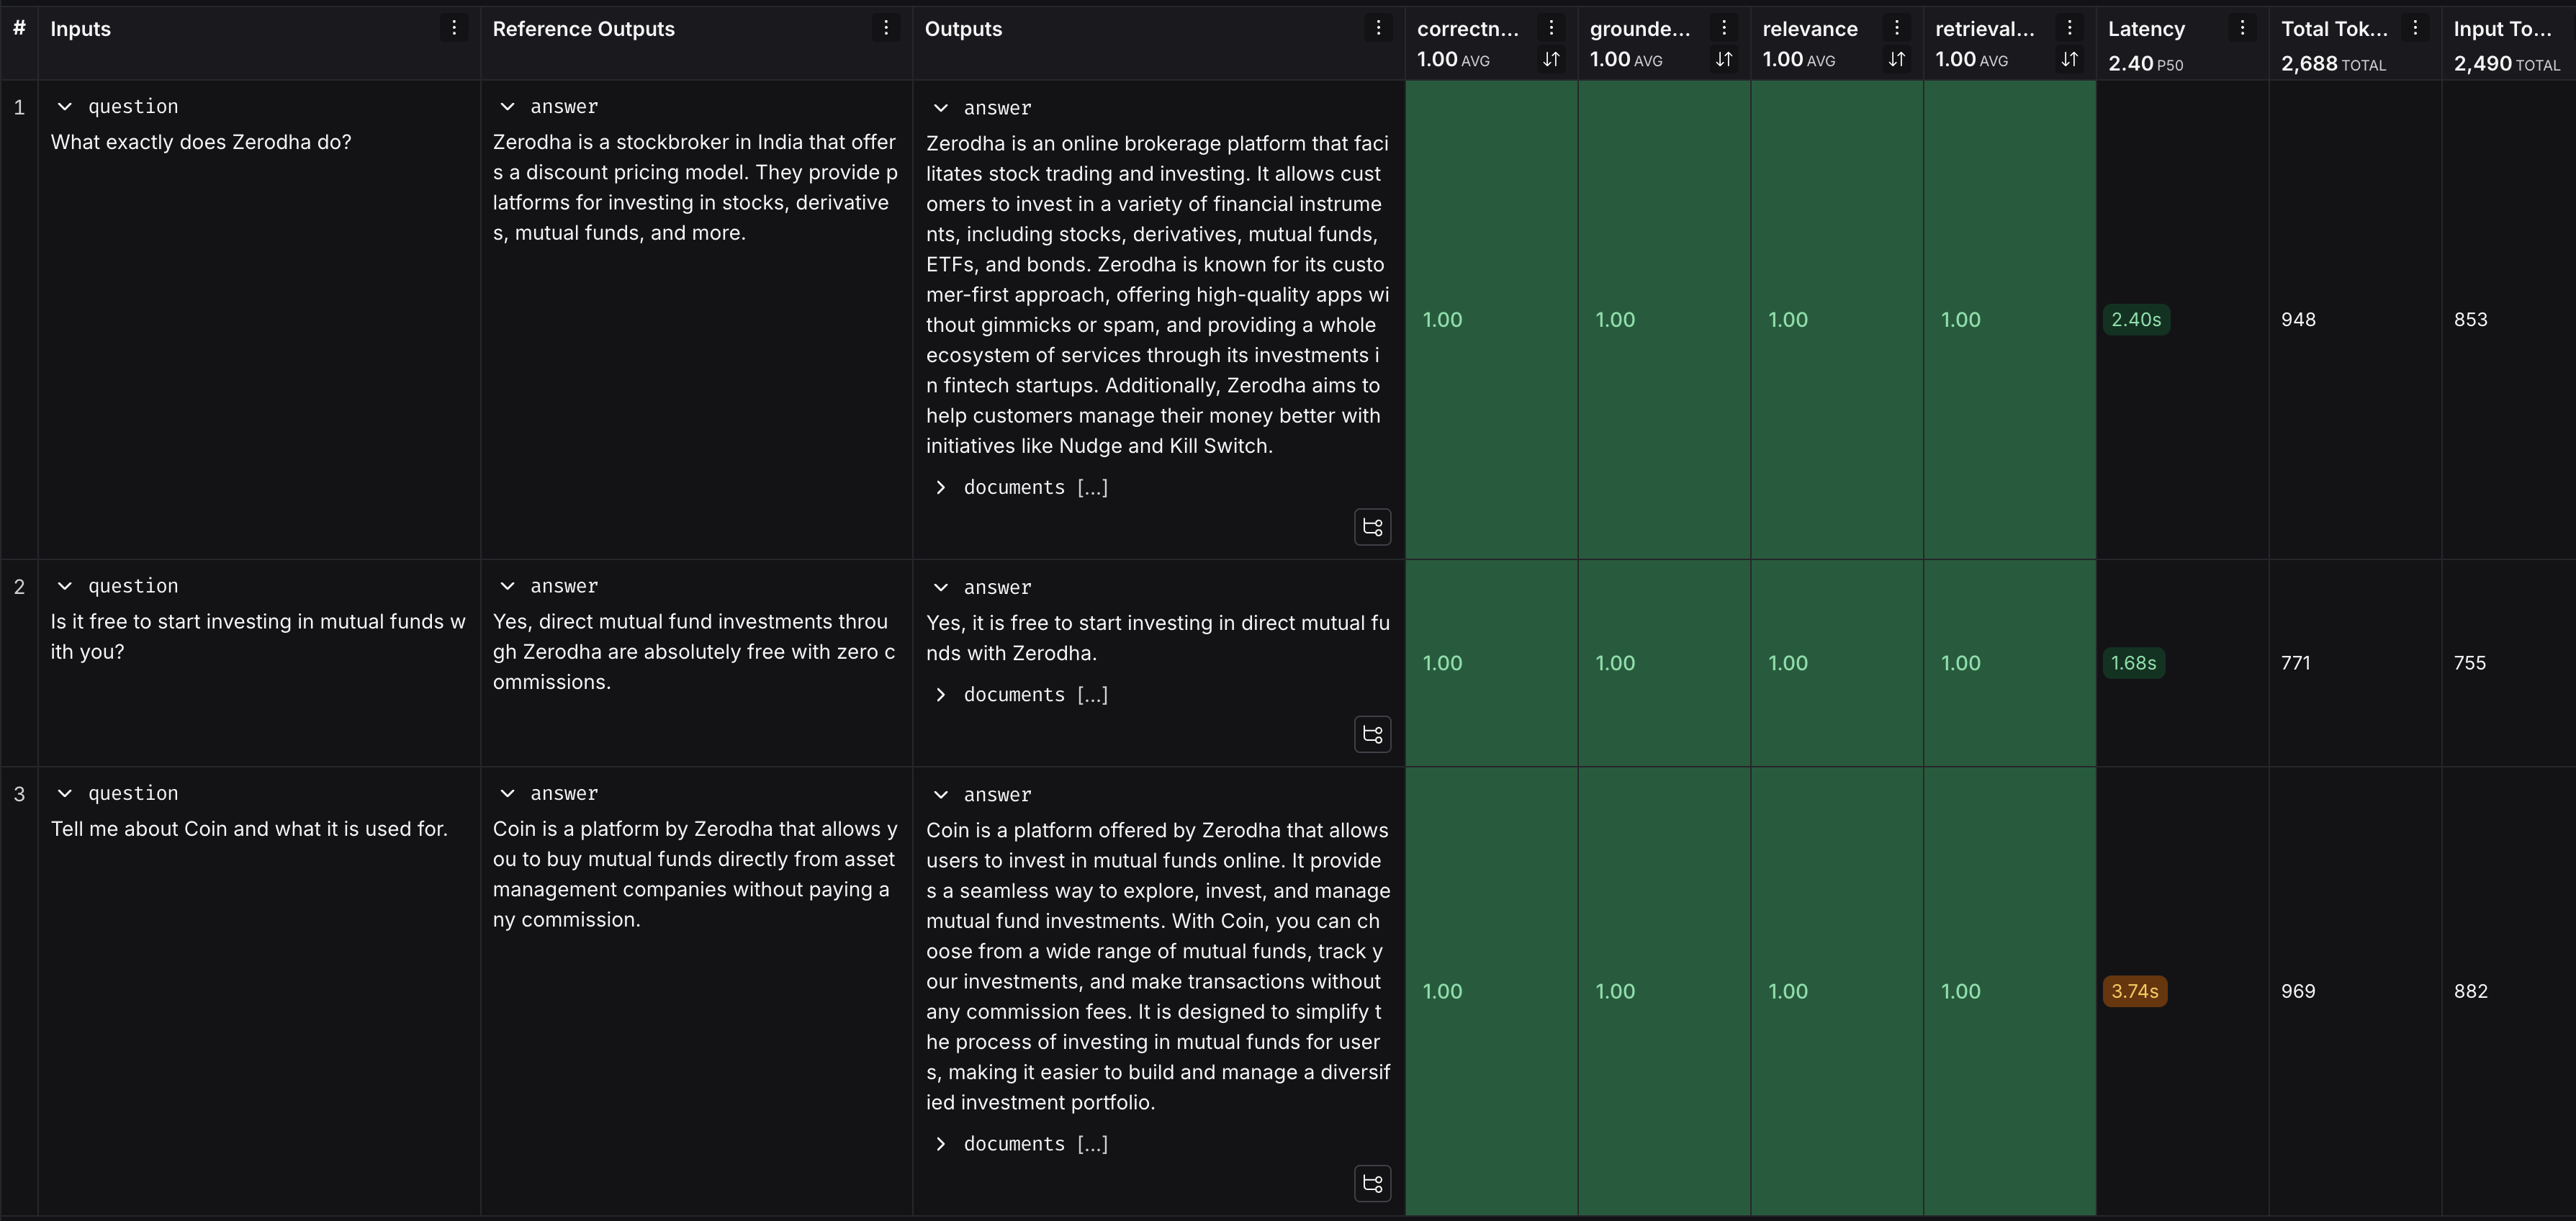

---

### Interpretation of RAG Evaluation Results

When you inspect your results, interpret the metrics like this:

1. **Correctness (`feedback.correctness`)**  
   - `True` means the final answer matches the dataset’s ground truth.  
   - `False` typically indicates one of these issues:
     - The retriever didn’t fetch the right context  
     - The prompt allowed the model to answer vaguely / incorrectly  
     - Your ground truth answer is misaligned with the source content

2. **Groundedness (`feedback.groundedness`)**  
   - `True` means the answer is supported by retrieved docs (no hallucination).  
   - `False` is a red flag that the model is inventing information beyond context.

3. **Relevance (`feedback.relevance`)**  
   - `True` means the answer actually addresses the user’s question.  
   - `False` often happens when the bot responds with:
     - Generic content  
     - Partial / off-topic explanation  
     - “I don’t know” even though relevant context exists

4. **Retrieval Relevance (`feedback.retrieval_relevance`)**  
   - `True` means the retriever is fetching context that has semantic alignment with the query.  
   - `False` suggests your chunking/indexing/retriever settings are misconfigured (or the KB itself is too thin).

---

### Ways to Improve the Zerodha Support Bot

1. **Improve Answer Generation**
   - Tighten the system instructions to *only answer from retrieved context*.
   - Add formatting constraints (stepwise answer, short bullets, cite which doc snippet was used).

2. **Enhance Retrieval Precision**
   - Tune chunk size / overlap.
   - Consider metadata filtering (if your loader provides structure).
   - Add a re-ranker (BM25 + dense, or dedicated re-ranking model).

3. **Reduce “I don’t know” failures**
   - If retrieval is relevant but answer is weak, improve the prompt to explicitly synthesize from context.
   - Add a fallback: “Here is what I found in the docs…” instead of “I don’t know.”

4. **Expand & Strengthen the Evaluation Dataset**
   - Add more user-like questions (edge cases, policy, pricing, troubleshooting).
   - Create multiple acceptable reference answers when phrasing can vary.



In [ ]:
from typing_extensions import Annotated, TypedDict
from typing import List
from langchain_openai import ChatOpenAI


class LabInterpretation(TypedDict):
    test_name: Annotated[str, ..., "Name of the primary lab test or panel"]
    status: Annotated[str, ..., "Overall status: normal, abnormal, or critical"]
    urgency: Annotated[str, ..., "Clinical urgency: routine, urgent, or stat"]
    abnormal_findings: Annotated[List[str], ..., "List of abnormal values with clinical significance"]
    interpretation: Annotated[str, ..., "Clinical interpretation of the results"]
    recommended_actions: Annotated[List[str], ..., "Recommended clinical follow-up actions"]


LAB_SYSTEM_PROMPT = """You are a clinical lab interpreter agent.
Given a lab report, identify the test panel, flag abnormal values, assess urgency, and provide a clinical interpretation.
Urgency levels: routine (minor deviations), urgent (significant abnormalities requiring same-day follow-up),
stat (critical values requiring immediate action).
Be concise and clinically precise."""


class LabAgent:
    def __init__(self, model: str = "gpt-4o-mini", temperature: float = 0.0):
        self._llm = ChatOpenAI(model=model, temperature=temperature).with_structured_output(
            LabInterpretation, method="json_schema", strict=True
        )

    def interpret(self, lab_report: str, patient_id: str) -> dict:
        try:
            result = self._llm.invoke([
                {"role": "system", "content": LAB_SYSTEM_PROMPT},
                {
                    "role": "user",
                    "content": f"Patient ID: {patient_id}\n\nLab Report:\n{lab_report}",
                },
            ])
            return {"success": True, "patient_id": patient_id, "result": result}
        except Exception as e:
            return {"success": False, "patient_id": patient_id, "error": str(e)}


lab_agent = LabAgent()

In [ ]:
from typing_extensions import Annotated, TypedDict
from typing import List
from langchain_openai import ChatOpenAI


class RadiologyAnalysis(TypedDict):
    modality: Annotated[str, ..., "Imaging modality, e.g. X-Ray, CT, MRI, Ultrasound"]
    body_region: Annotated[str, ..., "Anatomical region imaged"]
    primary_finding: Annotated[str, ..., "The main radiological finding or impression"]
    secondary_findings: Annotated[List[str], ..., "Additional findings noted in the report"]
    differential_diagnoses: Annotated[List[str], ..., "Possible diagnoses consistent with the findings"]
    urgency: Annotated[str, ..., "Clinical urgency: routine, urgent, or stat"]
    recommended_actions: Annotated[List[str], ..., "Recommended follow-up imaging or clinical actions"]


RADIOLOGY_SYSTEM_PROMPT = """You are a radiology analyzer agent with expertise in interpreting imaging reports.
Given a radiology report, identify the modality, body region, primary and secondary findings,
suggest differential diagnoses, assess urgency, and recommend follow-up actions.
Urgency levels: routine (incidental or stable findings), urgent (significant findings needing same-day review),
stat (critical findings requiring immediate clinical intervention).
Be clinically precise and concise."""


class RadiologyAgent:
    def __init__(self, model: str = "gpt-4o-mini", temperature: float = 0.0):
        self._llm = ChatOpenAI(model=model, temperature=temperature).with_structured_output(
            RadiologyAnalysis, method="json_schema", strict=True
        )

    def analyze(self, radiology_report: str, patient_id: str) -> dict:
        try:
            result = self._llm.invoke([
                {"role": "system", "content": RADIOLOGY_SYSTEM_PROMPT},
                {
                    "role": "user",
                    "content": f"Patient ID: {patient_id}\n\nRadiology Report:\n{radiology_report}",
                },
            ])
            return {"success": True, "patient_id": patient_id, "result": result}
        except Exception as e:
            return {"success": False, "patient_id": patient_id, "error": str(e)}


radiology_agent = RadiologyAgent()

In [ ]:
# ============================================================================
# VALIDATION CELL 4.1: Test All Agents
# ============================================================================

print('AGENT VALIDATION TESTS')
print('='*60)

# Test Lab Agent
print('\n[Test 1] Lab Interpreter Agent')
lab_report = """CBC Report:
Hemoglobin: 10.2 g/dL (LOW)
WBC: 12,500 /uL (HIGH)
Platelet: 180,000 /uL (NORMAL)"""

result = lab_agent.interpret(lab_report, 'test-patient-001')
print(f"  Success: {result.get('success', False)}")
if result.get('success'):
    print(f"  Test: {result['result']['test_name']}")
    print(f"  Status: {result['result']['status']}")
    print(f"  Urgency: {result['result']['urgency']}")

# Test Radiology Agent
print('\n[Test 2] Radiology Analyzer Agent')
radiology_report = """Chest X-Ray:
Bilateral infiltrates in lower lobes.
No pleural effusion. Heart size normal.
Impression: Findings consistent with pneumonia."""

result = radiology_agent.analyze(radiology_report, 'test-patient-002')
print(f"  Success: {result.get('success', False)}")
if result.get('success'):
    print(f"  Primary Finding: {result['result']['primary_finding']}")
    print(f"  Urgency: {result['result']['urgency']}")

# Test Allergy Agent
print('\n[Test 3] Allergy Safety Agent')
allergy_doc = """Patient has documented peanut allergy.
Previous reaction: Severe anaphylaxis requiring epinephrine."""

result = allergy_agent.assess(allergy_doc, 'test-patient-003')
print(f"  Success: {result.get('success', False)}")
if result.get('success'):
    print(f"  Cross-reactivities: {result['result']['cross_reactivities']}")

In [ ]:
from typing_extensions import Annotated, TypedDict
from typing import List
from langchain_openai import ChatOpenAI


class AllergyAssessment(TypedDict):
    primary_allergen: Annotated[str, ..., "The main allergen identified from the document"]
    reaction_severity: Annotated[str, ..., "Severity: mild, moderate, or severe"]
    cross_reactivities: Annotated[List[str], ..., "List of substances with known cross-reactivity to the primary allergen"]
    safety_warnings: Annotated[List[str], ..., "Critical safety warnings for this allergy profile"]
    recommendations: Annotated[str, ..., "Clinical recommendations for managing this allergy"]


ALLERGY_SYSTEM_PROMPT = """You are a clinical allergy safety agent with expertise in allergen cross-reactivity.
Given a patient allergy document, extract the primary allergen and identify all known cross-reactive substances.
Cross-reactivity means substances that share similar proteins and may trigger an allergic reaction in a sensitized patient.

Be clinically accurate. For peanut allergy, cross-reactivities include: tree nuts (varies by individual),
legumes (soybeans, lentils, chickpeas, peas), lupin, and seeds (sesame in some cases).
For severe anaphylaxis cases, always include heightened safety warnings."""


class AllergyAgent:
    def __init__(self, model: str = "gpt-4o-mini", temperature: float = 0.0):
        self._llm = ChatOpenAI(model=model, temperature=temperature).with_structured_output(
            AllergyAssessment, method="json_schema", strict=True
        )

    def assess(self, allergy_document: str, patient_id: str) -> dict:
        try:
            result = self._llm.invoke([
                {"role": "system", "content": ALLERGY_SYSTEM_PROMPT},
                {
                    "role": "user",
                    "content": f"Patient ID: {patient_id}\n\nAllergy Document:\n{allergy_document}",
                },
            ])
            return {"success": True, "patient_id": patient_id, "result": result}
        except Exception as e:
            return {"success": False, "patient_id": patient_id, "error": str(e)}


allergy_agent = AllergyAgent()

In [ ]:
print("\n[Test 3] Allergy Safety Agent")
allergy_doc = """Patient has documented peanut allergy.
Previous reaction: Severe anaphylaxis requiring epinephrine."""

result = allergy_agent.assess(allergy_doc, "test-patient-003")
print(f"  Success: {result.get('success', False)}")
if result.get('success'):
    print(f"  Cross-reactivities: {result['result']['cross_reactivities']}")
    print(f"  Severity: {result['result']['reaction_severity']}")
    print(f"  Safety warnings: {result['result']['safety_warnings']}")